# 02 — Identification of the drone with an RNN (step 3 of the subject)

**Goal:** learn a model that, given the command **u**, predicts the vertical acceleration **az** of the drone.
This model will later be the "simulator" inside the RL environment (Track B).

**Model (course 6.2, "State Space Neural Network"):**

$$h_{k+1} = \tanh(W_{xh}\,u_k + W_{hh}\,h_k + b_h), \qquad \hat a_z(k+1) = W_{hy}\,h_{k+1} + b_y$$

- $h$ is the hidden state (the network's memory, here 32 numbers). It plays the role of the internal state of the motors.
- Input $u_k$ = command applied at step k, output = acceleration at step **k+1**: the command needs one step to act (seen in notebook 01).
  This is also exactly what the RL environment needs: "I apply u now, what is the acceleration at the next step?"

**Key point — free-run simulation:** the network only receives u, never the measured az. It must reproduce az on its own over the whole
experiment (100 s = 2000 steps). This is harder than predicting one step ahead from measurements, but it is how the model will be used in RL.

**Comparison (asked by the subject):** a linear model (ARX, least squares), evaluated the same way.

**Inputs:** `data/processed/dataset_v1.npz` (produced by notebook 01).
**Output:** `results/models/rnn_az.pt` (trained model, ignored by Git) + figures in `results/figures/`.

In [ ]:
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ---- Paths (the notebook is in notebooks/, everything else is one level up) ----
DATA_FILE = Path('../data/processed/dataset_v1.npz')
MODEL_DIR = Path('../results/models'); MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path('../results/figures'); FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- Settings (all the choices are here, so they are easy to find and change) ----
SEED = 0          # same random numbers for everyone -> reproducible results
HIDDEN = 32       # size H of the hidden state h (memory of the RNN)
T_TRAIN = 600     # training on the first 600 steps (30 s) of each experiment, see explanation below
BATCH = 64        # number of experiments used for one weight update
EPOCHS = 60       # number of passes over the training set (~2-4 min on a laptop CPU)
LR = 3e-3         # learning rate of Adam (size of the weight updates at the start)

torch.manual_seed(SEED)
np.random.seed(SEED)

## 1. Data

We reuse the split of notebook 01 (train / validation / test, by whole experiments).
Values are **normalized** (mean 0, std 1, constants computed on the training set only): networks learn badly when values are large
(az goes from -30 to +10, which would saturate the tanh).

**Why train on 30 s only?** Each experiment starts at rest (u = 0 for 2 s), so starting the memory at h = 0 is correct.
Cutting a window in the middle of a flight would start with a wrong memory. 30 s already contains ~25 command steps, and training on
shorter sequences is faster and more stable (vanishing / exploding gradients, course 7). Validation and test use the **full 100 s**:
this checks that the model stays accurate on long horizons.

In [ ]:
d = np.load(DATA_FILE)
U_MEAN, U_STD = float(d['u_mean']), float(d['u_std'])      # normalization of the input u
AZ_MEAN, AZ_STD = float(d['az_mean']), float(d['az_std'])  # normalization of the output az
Ts = float(d['Ts'])

def to_tensors(U, Y, n_steps=None):
    """Raw arrays (experiments x time) -> normalized tensors (experiments x time x 1).
    Input = u(k), target = az(k+1): we drop the last u and the first az to shift by one step."""
    if n_steps is not None:                      # keep only the beginning of each experiment
        U, Y = U[:, :n_steps], Y[:, :n_steps]
    x = (U[:, :-1] - U_MEAN) / U_STD             # u(0) ... u(N-2)
    y = (Y[:, 1:] - AZ_MEAN) / AZ_STD            # az(1) ... az(N-1)
    # PyTorch expects the shape (batch, time, features); unsqueeze(-1) adds the "features" axis of size 1
    return (torch.tensor(x, dtype=torch.float32).unsqueeze(-1),
            torch.tensor(y, dtype=torch.float32).unsqueeze(-1))

x_train, y_train = to_tensors(d['U_train'], d['Y_train'], T_TRAIN)
x_val, y_val = to_tensors(d['U_val'], d['Y_val'])        # full 100 s
x_test, y_test = to_tensors(d['U_test'], d['Y_test'])    # full 100 s, used only once at the end

print('train', tuple(x_train.shape), '| val', tuple(x_val.shape), '| test', tuple(x_test.shape))

## 2. Linear reference model (ARX, least squares — course 3)

$$a_z(k+1) = a_1\,a_z(k) + a_2\,a_z(k-1) + b_1\,u(k) + b_2\,u(k-1) + c$$

The 5 coefficients are found by least squares on the training set (one linear system to solve, no iterations).
Then the model is simulated in free run: it reuses its **own** predictions of az, like the RNN.

In [ ]:
def arx_regressors(U, Y):
    """Build the least-squares problem: each row = [az(k), az(k-1), u(k), u(k-1), 1], target = az(k+1)."""
    X = np.stack([Y[:, 1:-1], Y[:, :-2], U[:, 1:-1], U[:, :-2], np.ones_like(U[:, 1:-1])], axis=-1)
    return X.reshape(-1, 5), Y[:, 2:].reshape(-1)

X, target = arx_regressors(d['U_train'], d['Y_train'])
theta = np.linalg.lstsq(X, target, rcond=None)[0]           # least-squares solution
print('ARX coefficients [a1, a2, b1, b2, c] =', np.round(theta, 4))

def simulate_arx(U, theta):
    """Free-run simulation: start at rest (az = -g, the value measured when u = 0), then reuse the predictions."""
    a1, a2, b1, b2, c = theta
    az = np.full(U.shape, float(d['Y_train'][:, 0].mean()))  # initial value of az at rest (~ -9.81)
    for k in range(1, U.shape[1] - 1):
        az[:, k + 1] = a1 * az[:, k] + a2 * az[:, k - 1] + b1 * U[:, k] + b2 * U[:, k - 1] + c
    return az

## 3. The RNN

`nn.RNN` implements exactly the equation of the course, $h_{k+1} = \tanh(W_{xh}u_k + W_{hh}h_k + b)$, with an efficient loop over time.
A linear layer then reads the memory to give az. The `forward` function returns the new hidden state too: this is what will let the
RL environment run the model **one step at a time** (section 6).

In [ ]:
class RNNModel(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        # Recurrent layer: input size 1 (u), memory size H. batch_first=True -> shape (batch, time, features)
        # Parameters inside: W_xh (H x 1), W_hh (H x H) and the bias b_h (PyTorch stores it as two vectors that are added)
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, nonlinearity='tanh', batch_first=True)
        # Output layer: az = W_hy h + b_y  (W_hy is 1 x H)
        self.out = nn.Linear(hidden_size, 1)

    def forward(self, u, h=None):
        # u: (batch, time, 1) normalized commands. h: memory to start from (None = zeros = drone at rest)
        hs, h_last = self.rnn(u, h)   # hs: memory at every step (batch, time, H); h_last: memory after the last step
        return self.out(hs), h_last   # predicted normalized az at every step, and the memory to continue from

model = RNNModel(HIDDEN)
print(model)
print('number of parameters:', sum(p.numel() for p in model.parameters()))

## 4. Training

At each epoch, the training experiments are shuffled and cut into mini-batches of 64. For each mini-batch:
prediction over 30 s → error (MSE) → gradients by backpropagation through time (BPTT) → update of the weights (Adam).

- **Gradient clipping:** limits the size of the update, protects against exploding gradients (typical of RNNs).
- **Cosine learning rate:** the learning rate decreases smoothly from `LR` to 0, which gives a cleaner final model.
- **Best model kept:** after each epoch we measure the error on the validation set (never used to update the weights)
  and we keep the weights of the best epoch. This avoids overfitting.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
loss_fn = nn.MSELoss()

def rmse_ms2(pred, target):
    """Error in physical units (m/s^2): RMSE on normalized values x standard deviation of az."""
    return torch.sqrt(loss_fn(pred, target)).item() * AZ_STD

history, best_val, best_state = [], float('inf'), None
for epoch in range(EPOCHS):
    model.train()
    order = torch.randperm(len(x_train))                     # new random order of experiments at each epoch
    for i in range(0, len(x_train), BATCH):
        batch = order[i:i + BATCH]
        optimizer.zero_grad()                                 # reset the gradients of the previous step
        pred, _ = model(x_train[batch])                       # free-run prediction over 30 s
        loss = loss_fn(pred, y_train[batch])                  # mean squared error
        loss.backward()                                       # gradients (BPTT)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)     # gradient clipping
        optimizer.step()                                      # update of the weights
    scheduler.step()                                          # lower the learning rate a bit

    model.eval()
    with torch.no_grad():                                     # no gradient needed to evaluate
        val = rmse_ms2(model(x_val)[0], y_val)               # free run over the full 100 s
    history.append(val)
    if val < best_val:                                        # keep a copy of the best weights
        best_val = val
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    if epoch % 5 == 0 or epoch == EPOCHS - 1:
        print(f'epoch {epoch:3d} | validation RMSE {val:.3f} m/s^2')

model.load_state_dict(best_state)                             # go back to the best epoch
print(f'best validation RMSE: {best_val:.3f} m/s^2')

plt.figure(figsize=(6, 3.5))
plt.semilogy(history); plt.xlabel('epoch'); plt.ylabel('validation RMSE [m/s²]'); plt.grid(True, which='both')
plt.title('RNN training'); plt.savefig(FIG_DIR / '08_rnn_training.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Test: RNN vs linear model (free run, 100 s, experiments never seen)

The measurement noise is ~0.045 m/s² (notebook 01): no model can go below this value, because it is compared to noisy measurements.

Test RMSE (free run, 450 experiments x 100 s):
  linear ARX : 0.835 m/s^2
  RNN        : 0.105 m/s^2
  (noise level of the measurements: 0.045 m/s^2)


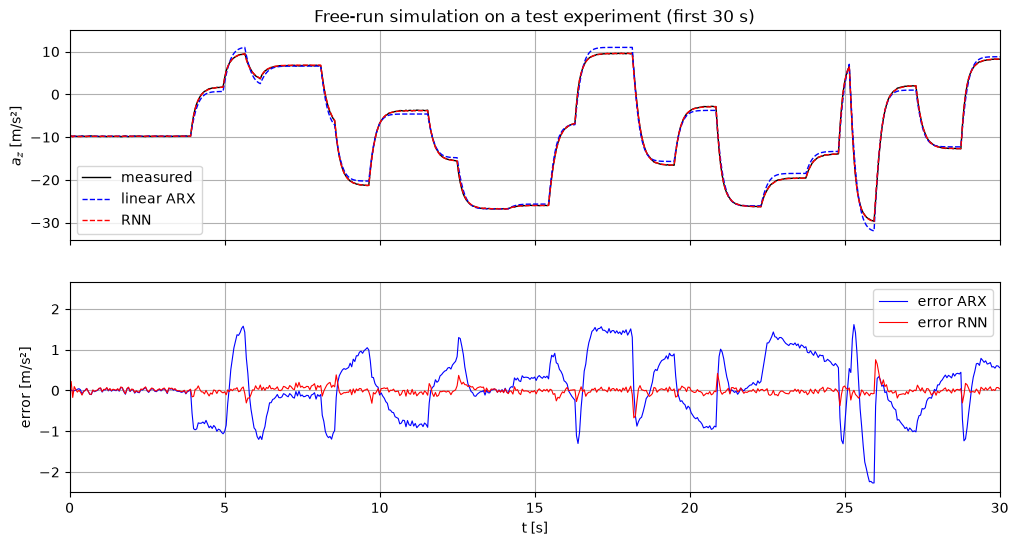

In [ ]:
model.eval()
with torch.no_grad():
    az_rnn = model(x_test)[0].squeeze(-1).numpy() * AZ_STD + AZ_MEAN   # back to m/s^2
az_true = d['Y_test'][:, 1:]                                           # measured az(1) ... az(N-1)
az_arx = simulate_arx(d['U_test'], theta)[:, 1:]

rmse = lambda pred: np.sqrt(np.mean((pred - az_true) ** 2))
print(f'Test RMSE (free run, {len(az_true)} experiments x 100 s):')
print(f'  linear ARX : {rmse(az_arx):.3f} m/s^2')
print(f'  RNN        : {rmse(az_rnn):.3f} m/s^2')
print(f'  (noise level of the measurements: {float(d["noise_std"]):.3f} m/s^2)')

i, t = 0, np.arange(1, az_true.shape[1] + 1) * Ts          # first test experiment
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(t, az_true[i], 'k', lw=1, label='measured')
ax[0].plot(t, az_arx[i], 'b--', lw=1, label='linear ARX')
ax[0].plot(t, az_rnn[i], 'r--', lw=1, label='RNN')
ax[0].set_ylabel('$a_z$ [m/s²]'); ax[0].legend(); ax[0].grid(); ax[0].set_xlim(0, 30)
ax[1].plot(t, az_arx[i] - az_true[i], 'b', lw=0.8, label='error ARX')
ax[1].plot(t, az_rnn[i] - az_true[i], 'r', lw=0.8, label='error RNN')
ax[1].set_ylabel('error [m/s²]'); ax[1].set_xlabel('t [s]'); ax[1].legend(); ax[1].grid()
ax[0].set_title('Free-run simulation on a test experiment (first 30 s)')
plt.savefig(FIG_DIR / '09_rnn_vs_arx_test.png', dpi=150, bbox_inches='tight'); plt.show()

## 6. Robustness: worst cases on long, never-seen simulations

The global RMSE of section 5 is an **average**: it can hide a few experiments (or a few moments) where the model is badly wrong.
For the RL agent, these worst cases matter most: if the model is wrong in some situation, the agent may learn a behaviour that fails
on the real drone. Two checks:

**6.1 — Validation and test sets (100 s each, never used to update the weights):** error of every experiment, the worst ones kept and
plotted, and the error as a function of time. The model was trained on 30 s sequences: if its error grew with time (drift of the memory),
it would show here, since these runs are more than 3 times longer.

**6.2 — Very long simulations (10 min each) generated with Simulink** by `gen_long_data.m` (in `Matlab files`). They are new commands
never seen by the model, 20 times longer than the training sequences, and **without noise** (`g_noise = 0`): the error is then purely the
model error.

In [ ]:
def free_run_errors(U, Y):
    """Free-run simulation of the RNN on raw arrays (experiments x time). Returns the error predicted - measured, in m/s^2."""
    x, _ = to_tensors(U, Y)
    with torch.no_grad():
        az_pred = model(x)[0].squeeze(-1).numpy() * AZ_STD + AZ_MEAN
    return az_pred - Y[:, 1:]                       # shape (experiments, time), aligned with az(1) ... az(N-1)

N_WORST = 3                                         # number of worst experiments kept per set
worst = {}                                          # name of the set -> list of (index, max error) of its worst experiments
for name, U, Y in [('validation', d['U_val'], d['Y_val']), ('test', d['U_test'], d['Y_test'])]:
    err = free_run_errors(U, Y)
    rmse_exp = np.sqrt(np.mean(err ** 2, axis=1))  # one RMSE per experiment
    max_exp = np.max(np.abs(err), axis=1)           # largest instantaneous error of each experiment
    order = np.argsort(max_exp)[::-1][:N_WORST]     # experiments sorted from the largest max error
    worst[name] = [(int(i), float(max_exp[i])) for i in order]
    print(f'--- {name}: {len(U)} experiments x 100 s')
    print(f'  RMSE per experiment : median {np.median(rmse_exp):.3f} | 95 % below {np.percentile(rmse_exp, 95):.3f} | worst {rmse_exp.max():.3f} m/s^2')
    print(f'  max |error|         : median {np.median(max_exp):.3f} | 95 % below {np.percentile(max_exp, 95):.3f} | worst {max_exp.max():.3f} m/s^2')
    print(f'  {N_WORST} worst experiments (index in the set, max |error|):', [(i, round(e, 3)) for i, e in worst[name]])
    if name == 'validation':
        err_val = err                               # kept for the "error vs time" plot below

In [ ]:
# Plot the worst validation experiments, zoomed on +/- 4 s around their largest error
fig, axs = plt.subplots(N_WORST, 1, figsize=(12, 3 * N_WORST))
for ax, (i, e_max) in zip(axs, worst['validation']):
    az_meas = d['Y_val'][i, 1:]
    az_pred = az_meas + err_val[i]                  # prediction = measurement + error
    k = np.argmax(np.abs(err_val[i]))               # time index of the largest error
    t = np.arange(1, len(az_meas) + 1) * Ts
    ax.plot(t, az_meas, 'k', lw=1, label='measured')
    ax.plot(t, az_pred, 'r--', lw=1, label='RNN (free run)')
    ax2 = ax.twinx(); ax2.step(t, d['U_val'][i, :-1], 'g', where='post', lw=0.8, alpha=0.6); ax2.set_ylabel('u', color='g')
    ax.set_xlim(t[k] - 4, t[k] + 4); ax.set_ylabel('$a_z$ [m/s²]'); ax.grid(); ax.legend(loc='upper left')
    ax.set_title(f'validation experiment {i}: max |error| = {e_max:.2f} m/s² at t = {t[k]:.2f} s')
plt.tight_layout(); plt.savefig(FIG_DIR / '10_rnn_worst_cases.png', dpi=150, bbox_inches='tight'); plt.show()

# Error as a function of time, over all validation experiments: does it grow with time?
t = np.arange(1, err_val.shape[1] + 1) * Ts
plt.figure(figsize=(12, 3.5))
plt.plot(t, np.sqrt(np.mean(err_val ** 2, axis=0)), lw=0.8, label='RMSE over the validation experiments, at each instant')
plt.plot(t, np.max(np.abs(err_val), axis=0), lw=0.8, alpha=0.7, label='largest |error| among the experiments, at each instant')
plt.axvline(T_TRAIN * Ts, color='k', ls=':', label='length of the training sequences (30 s)')
plt.xlabel('t [s]'); plt.ylabel('error [m/s²]'); plt.grid(); plt.legend()
plt.title('Error vs time (must stay flat after 30 s: otherwise the memory drifts)')
plt.savefig(FIG_DIR / '11_rnn_error_vs_time.png', dpi=150, bbox_inches='tight'); plt.show()

**What to look at:**
- the worst experiments: is the large error a short peak at a sudden change of u (acceptable), or a lasting offset (problem)?
- in which situations: large commands near the saturation (u close to ±1), or quick successions of steps?
- the error vs time curve must stay flat after 30 s: otherwise the memory drifts on long horizons.

### 6.2 Long simulations (10 min, Simulink, without noise)

Run `gen_long_data` in MATLAB (folder `Matlab files`), then copy `long_u.csv` and `long_az.csv` into `results/long_sims/`
(or change `LONG_DIR` below to the folder where they are).

In [ ]:
LONG_DIR = Path('../results/long_sims')            # folder containing long_u.csv and long_az.csv
if not (LONG_DIR / 'long_u.csv').exists():
    print(f'No long simulations found in {LONG_DIR.resolve()}: run gen_long_data.m in MATLAB and copy the 2 CSV files here.')
else:
    U_long = np.loadtxt(LONG_DIR / 'long_u.csv', delimiter=',', ndmin=2)   # one row = one simulation of 10 min
    Y_long = np.loadtxt(LONG_DIR / 'long_az.csv', delimiter=',', ndmin=2)
    err_long = free_run_errors(U_long, Y_long)
    rmse_long = np.sqrt(np.mean(err_long ** 2, axis=1))
    max_long = np.max(np.abs(err_long), axis=1)
    print(f'{len(U_long)} simulations x {U_long.shape[1] * Ts:.0f} s (no noise: the error is the model error only)')
    for j in range(len(U_long)):
        print(f'  simulation {j}: RMSE {rmse_long[j]:.3f} m/s^2 | max |error| {max_long[j]:.3f} m/s^2 at t = {(np.argmax(np.abs(err_long[j])) + 1) * Ts:.1f} s')

    j = int(np.argmax(max_long))                    # simulation containing the largest error
    t = np.arange(1, err_long.shape[1] + 1) * Ts
    fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    ax[0].plot(t, Y_long[j, 1:], 'k', lw=0.8, label='Simulink (no noise)')
    ax[0].plot(t, Y_long[j, 1:] + err_long[j], 'r--', lw=0.8, label='RNN (free run)')
    ax[0].set_ylabel('$a_z$ [m/s²]'); ax[0].legend(); ax[0].grid()
    ax[1].plot(t, err_long[j], 'r', lw=0.6); ax[1].set_ylabel('error [m/s²]'); ax[1].set_xlabel('t [s]'); ax[1].grid()
    ax[0].set_title(f'Worst long simulation ({j}): RMSE {rmse_long[j]:.3f}, max |error| {max_long[j]:.3f} m/s²')
    plt.savefig(FIG_DIR / '12_rnn_long_simulation.png', dpi=150, bbox_inches='tight'); plt.show()

## 7. Saving, and using the model one step at a time (as in the RL environment)

In the environment, the agent chooses u at each step, so the model must be called **step by step**, carrying its memory h from one
call to the next. We check that this gives exactly the same result as the full-sequence prediction.

In [ ]:
torch.save({'state_dict': model.state_dict(), 'hidden': HIDDEN,
            'u_mean': U_MEAN, 'u_std': U_STD, 'az_mean': AZ_MEAN, 'az_std': AZ_STD, 'Ts': Ts},
           MODEL_DIR / 'rnn_az.pt')
print('saved:', (MODEL_DIR / 'rnn_az.pt').resolve())

# Step-by-step use: this is the pattern the environment will follow
u_seq = d['U_test'][0]                    # commands of one test experiment
h = None                                  # memory at rest
az_steps = []
with torch.no_grad():
    for u in u_seq[:-1]:
        u_norm = torch.tensor([[[(u - U_MEAN) / U_STD]]], dtype=torch.float32)  # shape (1 batch, 1 step, 1 feature)
        az_norm, h = model(u_norm, h)                                            # one step, memory updated
        az_steps.append(az_norm.item() * AZ_STD + AZ_MEAN)
print('max difference step-by-step vs full sequence:', np.max(np.abs(np.array(az_steps) - az_rnn[0])), 'm/s^2')

## Summary (to fill in after running)

- RNN with H = 32 (≈ 1 150 parameters), trained on 30 s sequences, validated in free run over 100 s.
- Test RMSE: RNN vs linear ARX → the linear model cannot reproduce the saturation (tanh) seen in notebook 01, the RNN can.
- The model can be run one step at a time with its memory h: it is ready to be wrapped in the Gymnasium environment
  (az → vz → z by integration, `info["m"]` for the export).